In [91]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import seaborn as sns

import pandas as pd
import numpy as np

### Q1 — Data exploration and preprocessing

1.1 Load the dataset

In [92]:
df = pd.read_csv("CAB330_asm2_datasets 2/Dataset4Task1_26.csv")

print(df.shape)
print(df.info())

(4898, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         4890 non-null   float64
 1   volatile acidity      4892 non-null   float64
 2   citric acid           4895 non-null   float64
 3   residual sugar        4893 non-null   float64
 4   chlorides             4893 non-null   float64
 5   free sulfur dioxide   4896 non-null   float64
 6   total sulfur dioxide  4893 non-null   float64
 7   density               4892 non-null   float64
 8   pH                    4895 non-null   float64
 9   sulphates             4894 non-null   float64
 10  alcohol               4897 non-null   float64
dtypes: float64(11)
memory usage: 421.0 KB
None


1.2 Identify missing values

In [93]:
# There are 48 missing entries across the dataset.
df.isna().sum()

fixed acidity           8
volatile acidity        6
citric acid             3
residual sugar          5
chlorides               5
free sulfur dioxide     2
total sulfur dioxide    5
density                 6
pH                      3
sulphates               4
alcohol                 1
dtype: int64

K-Means cannot directly process missing values represented by NaN. Therefore, they must be handled before clustering.

1.3 Treating duplicate and Missing values

In [94]:
print("Duplicates:", df.duplicated().sum())

Duplicates: 923


In [95]:
# Check original dataset
print("Original shape:", df.shape)

# Remove exact duplicates
df_clean = df.drop_duplicates().copy()

print("After removing duplicates:", df_clean.shape)

# Replace missing values with median
df_clean = df_clean.fillna(df_clean.median())

# Verify preprocessing
print("Missing values after:")
print(df_clean.isna().sum())

print("Remaining duplicates:", df_clean.duplicated().sum())

# Save cleaned dataset
df_clean.to_csv("Task1_cleaned.csv", index=False)

Original shape: (4898, 11)
After removing duplicates: (3975, 11)
Missing values after:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
dtype: int64
Remaining duplicates: 0


* 923 duplicate was identified and removed the first occurence of the duplicate to avoid them to disproportionately influence the k means
* All missing values were imputated with mean

1.3 Investigate the distribution and outliers

In [96]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
count,4890.000000,4892.000000,4895.000000,4893.000000,4893.000000,4896.000000,4893.000000,4892.000000,4895.000000,4894.000000,4897.000000
mean,6.854775,0.278278,0.334180,6.391815,0.045757,35.309641,138.334253,0.994030,3.188337,0.489867,10.513964
std,0.844261,0.100835,0.121054,5.073152,0.021832,17.010290,42.486884,0.002991,0.150993,0.114149,1.230563
min,3.800000,0.080000,0.000000,0.600000,0.009000,2.000000,9.000000,0.987110,2.720000,0.220000,8.000000
25%,6.300000,0.210000,0.270000,1.700000,0.036000,23.000000,108.000000,0.991730,3.090000,0.410000,9.500000
50%,6.800000,0.260000,0.320000,5.200000,0.043000,34.000000,134.000000,0.993750,3.180000,0.470000,10.400000
75%,7.300000,0.320000,0.390000,9.900000,0.050000,46.000000,167.000000,0.996100,3.280000,0.550000,11.400000
max,14.200000,1.100000,1.660000,65.800000,0.346000,289.000000,440.000000,1.038980,3.820000,1.080000,14.200000


Huge gap between min and max values was identified in following variables. This suggests a right-skewed distribution with some unusually high values.
* residual sugar
* free sulfur dioxide
* total sulfur dioxide. 

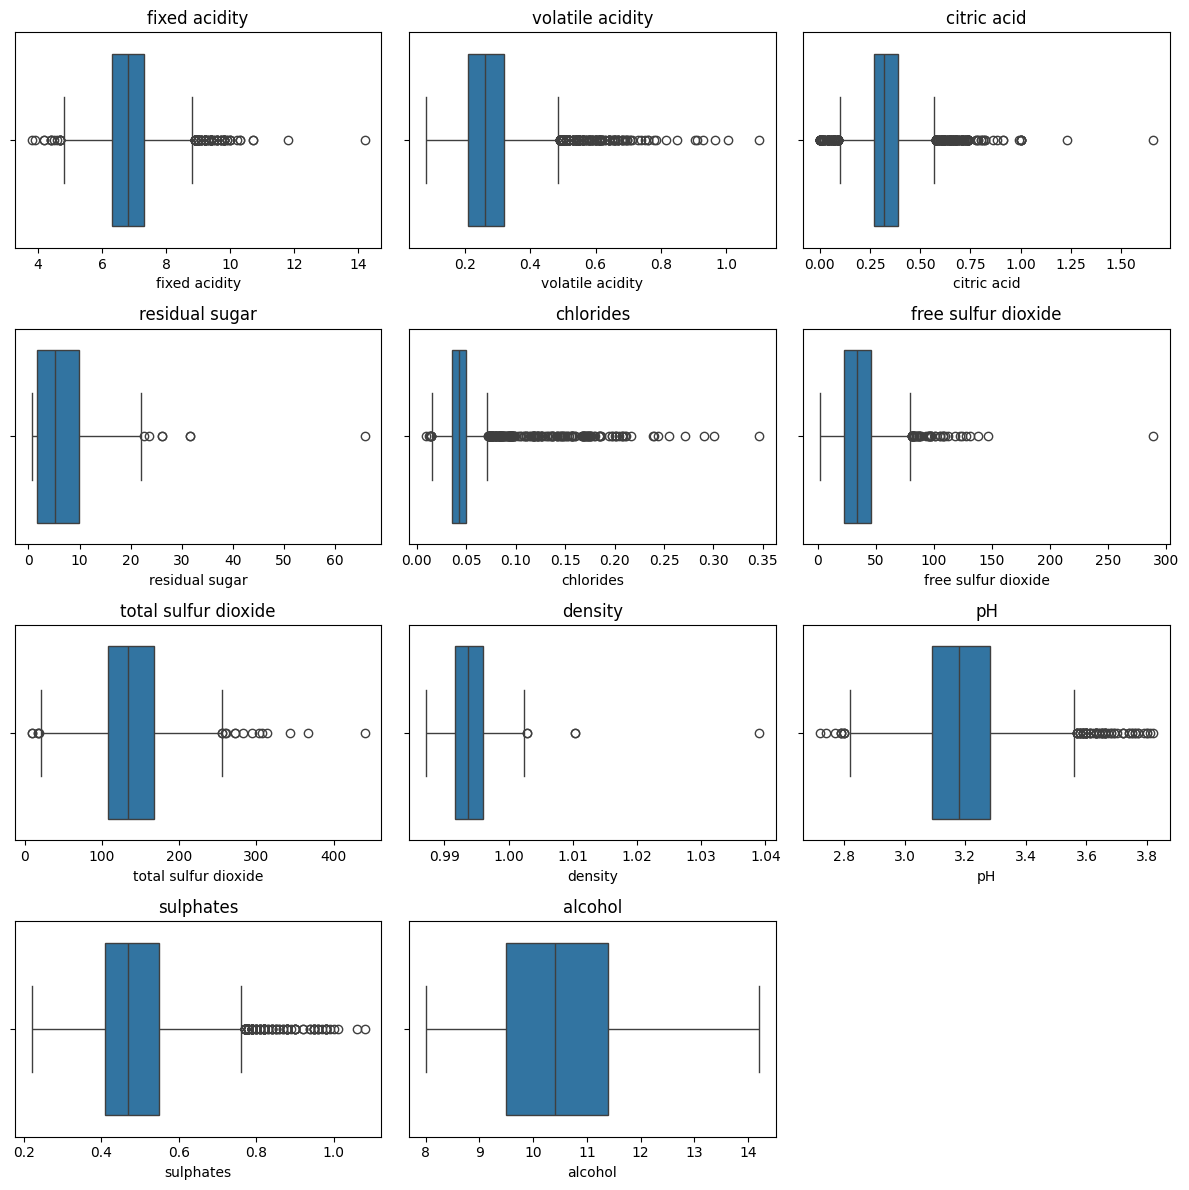

In [97]:
features = df.columns

fig, axes = plt.subplots(4, 3, figsize=(12, 12))
axes = axes.flatten()

for i, feature in enumerate(features):
    sns.boxplot(x=df[feature], ax=axes[i])
    axes[i].set_title(feature)

# remove unused subplot
for j in range(len(features), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Box plot shows more isolated outliers in the dataset. On top of the outliers observed with describe(), it shows 
* fixed cidity
* citric acid
* chlorides
* density has isolated outliers

In [98]:
# Inspect the five highest density observations
df.nlargest(5, 'density')[
    ['density', 'residual sugar', 'alcohol',
     'free sulfur dioxide', 'total sulfur dioxide']
]

,density,residual sugar,alcohol,free sulfur dioxide,total sulfur dioxide
2781,1.03898,65.80,11.7,8.0,160.0
1653,1.01030,31.60,8.8,35.0,176.0
1663,1.01030,31.60,8.8,35.0,176.0
3619,1.00295,26.05,10.6,27.0,122.0
3623,1.00295,26.05,10.6,27.0,122.0


### Q2

In [99]:
# Use all 11 features (as required by Q2)
X = df_clean.values 
rs = 42

clusters = []
inertia_vals = []
silhouette_vals = []

k_values = range(2, 17)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=rs, n_init=10)
    kmeans.fit(X)
    clusters.append(kmeans.labels_)
    inertia_vals.append(kmeans.inertia_)

    score = silhouette_score(X, kmeans.labels_, sample_size=1500, random_state=rs)
    silhouette_vals.append(score)

results = pd.DataFrame({
    'k': k_values,
    'inertia': inertia_vals,
    'silhouette': silhouette_vals
})
results


,k,inertia,silhouette
0,2,3.485596e+06,0.508637
1,3,2.291924e+06,0.405148
2,4,1.743155e+06,0.383172
3,5,1.456955e+06,0.352163
4,6,1.281602e+06,0.314285
5,7,1.142817e+06,0.328494
6,8,1.028361e+06,0.330245
7,9,9.345441e+05,0.303866
8,10,8.626870e+05,0.301051
9,11,7.911961e+05,0.303830


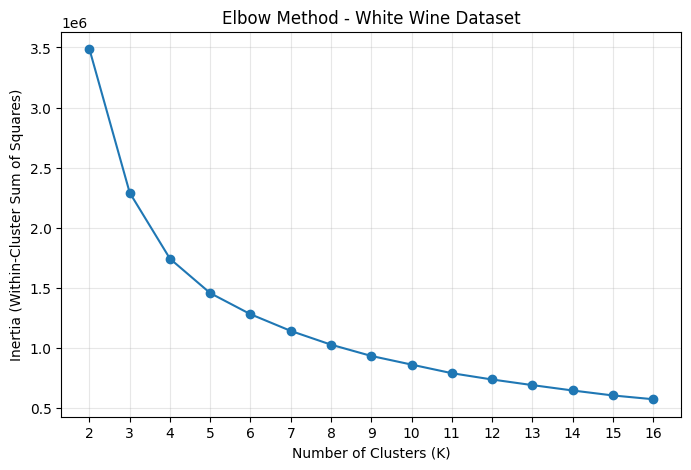

In [100]:
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia_vals, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia (Within-Cluster Sum of Squares)')
plt.title('Elbow Method - White Wine Dataset')
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.show()

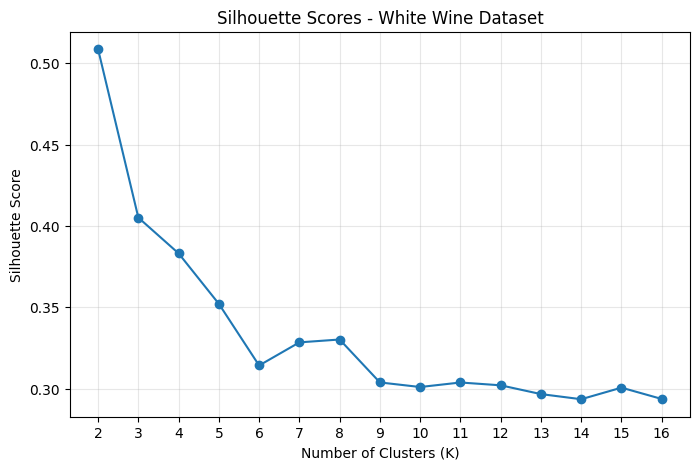

Best sampled silhouette K: 2


In [101]:

plt.figure(figsize=(8, 5))
plt.plot(k_values, silhouette_vals, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Scores - White Wine Dataset')
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.show()

print("Best sampled silhouette K:", k_values[results['silhouette'].argmax()])


In [102]:
for k in [3, 4]:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(df_clean.values)
    score = silhouette_score(df_clean.values, labels)
    print(f"K={k}, full silhouette score = {score:.6f}")

K=3, full silhouette score = 0.415094
K=4, full silhouette score = 0.377167


To determine the optimal number of clusters, K-Means models were trained for K values from 2 to 16 using all 11 variables. The Elbow Method was applied by plotting K against inertia (within-cluster sum of squares), and Silhouette Scores were also computed for each K value.  
The silhouette results indicated that K=2 achieved the highest score (0.5119), followed by K=3 (0.4031) and K=4 (0.3766). However, because the task requires partitioning the data into more than two clusters, K=2 was not considered further.  
The elbow plot showed a sharp decrease in inertia from K=2 to K=4, after which the curve began to flatten, indicating diminishing returns from additional clusters. Considering both criteria, K=4 was selected as the most appropriate clustering solution because it provides a good balance between cluster separation and model complexity.

### Q3

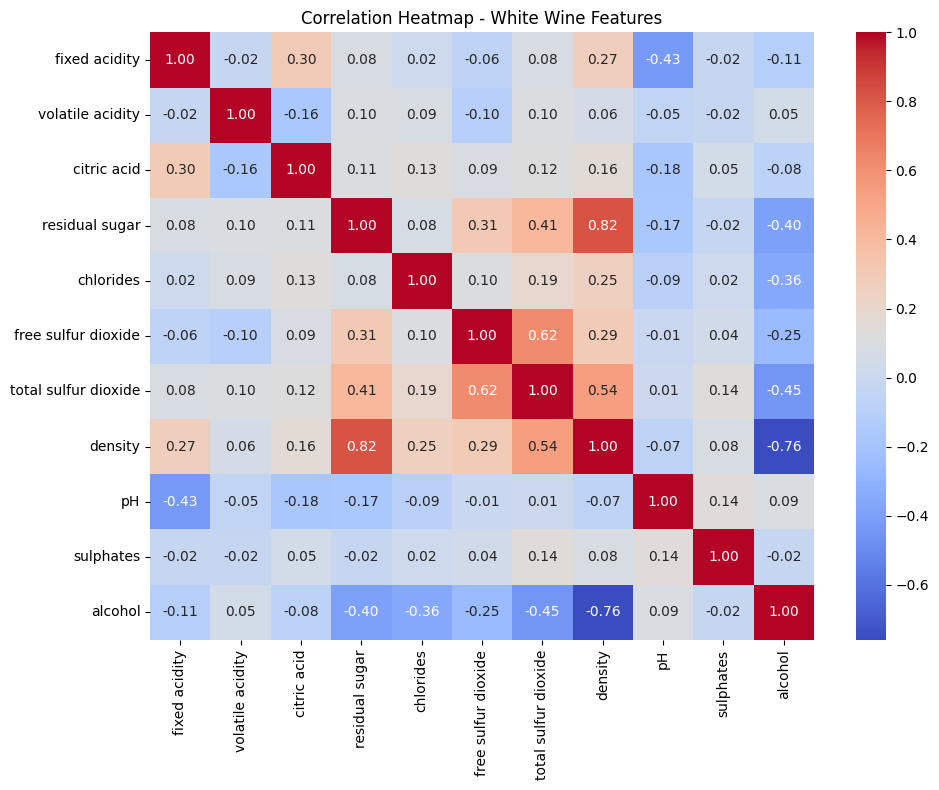

In [103]:
plt.figure(figsize=(10, 8))
sns.heatmap(df_clean.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap - White Wine Features')
plt.tight_layout()
plt.show()

In [104]:
# Baseline: all 11 features
X_all = df_clean.values

baseline_model = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

baseline_labels = baseline_model.fit_predict(X_all)
baseline_silhouette = silhouette_score(X_all, baseline_labels)

print("Baseline silhouette:", baseline_silhouette)

# Remove each feature one at a time
results = []

for feature in df_clean.columns:

    # Keep everything except the current feature
    remaining_features = [
        col for col in df_clean.columns
        if col != feature
    ]

    X_temp = df_clean[remaining_features].values

    model = KMeans(
        n_clusters=4,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_temp)

    score = silhouette_score(
        X_temp,
        labels
    )

    results.append({
        'Feature_Removed': feature,
        'Silhouette': score,
    })


feature_test = pd.DataFrame(results)

# Highest silhouette first
feature_test = feature_test.sort_values(
    'Silhouette',
    ascending=False
)

print(feature_test)

Baseline silhouette: 0.37716719965819373
         Feature_Removed  Silhouette
5    free sulfur dioxide    0.483934
6   total sulfur dioxide    0.430002
3         residual sugar    0.391772
10               alcohol    0.378263
0          fixed acidity    0.377947
8                     pH    0.377188
2            citric acid    0.377180
9              sulphates    0.377179
1       volatile acidity    0.377176
4              chlorides    0.377168
7                density    0.377167


* use the correlation heatmap to identify redundant variables and groups of strongly related features

* when two or more variables are strongly correlated, compare their effect on clustering using leave-one-feature-out silhouette scores

* remove free sulfur dioxide rather than total sulfur dioxide, because removing free sulfur dioxide increased the silhouette score more strongly

* remove density, residual sugar, and alcohol because they contain substantial overlapping information, particularly through the strong correlations involving density

* retain volatile acidity, citric acid, pH, and sulphates because they are comparatively independent and represent distinct physicochemical characteristics

* retain total sulfur dioxide because it contributes useful information while giving better clustering performance than retaining free sulfur dioxide

In [105]:
selected_features = [
    'volatile acidity',
    'citric acid',
    'pH',
    'sulphates',
    'total sulfur dioxide',
]

df_selected = df_clean[selected_features]

print(df_selected.head())
print(df_selected.shape)


   volatile acidity  citric acid    pH  sulphates  total sulfur dioxide
0              0.27         0.36  3.00       0.45                 170.0
1              0.30         0.34  3.30       0.49                 132.0
2              0.28         0.40  3.26       0.44                  97.0
3              0.23         0.32  3.19       0.40                 186.0
6              0.32         0.16  3.18       0.47                 136.0
(3975, 5)


In [106]:
# all features
X_all = df_clean.values

model_all = KMeans(n_clusters=4, random_state=42, n_init=10)
labels_all = model_all.fit_predict(X_all)
sil_all = silhouette_score(X_all, labels_all)

# selected 5 features
X_selected = df_selected.values

model_selected = KMeans(n_clusters=4, random_state=42, n_init=10)
labels_selected = model_selected.fit_predict(X_selected)
sil_selected = silhouette_score(X_selected, labels_selected)

print("All 11 features silhouette:", sil_all)
print("Selected 5 features silhouette:", sil_selected)

All 11 features silhouette: 0.37716719965819373
Selected 5 features silhouette: 0.5243291283316336


Feature selection was performed using a combination of correlation analysis and clustering-based evaluation. The correlation heatmap was first used to identify redundant variables, particularly groups of variables with strong relationships. For correlated features, leave-one-feature-out K-Means experiments were conducted using K=4, and the resulting silhouette scores were compared to determine which variables could be removed with the least loss, or greatest improvement, in cluster quality. This analysis showed that removing free sulfur dioxide produced the largest improvement in silhouette score, while total sulfur dioxide was retained. Additional variables with overlapping information or limited contribution were removed to reduce dimensionality. The final subset contained volatile acidity, citric acid, pH, sulphates and total sulfur dioxide. The reduced five-feature model achieved a silhouette score of 0.524, compared with 0.374 for the full 11-feature model, indicating improved cluster cohesion and separation.

### Q4

In [107]:

# selected feature matrix
X_selected = df_selected.values

# final K-means model
model_q4 = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# fit and predict cluster labels
labels_q4 = model_q4.fit_predict(X_selected)

# copy dataframe and add cluster labels
df_q4 = df_selected.copy()
df_q4['Cluster_ID'] = labels_q4

# Cluster membership
print("Cluster membership:")
print(df_q4['Cluster_ID'].value_counts().sort_index())

# Centroids
centroids = pd.DataFrame(
    model_q4.cluster_centers_,
    columns=selected_features
)

centroids.index.name = 'Cluster_ID'

print("\nCluster centroids:")
print(centroids)

# Silhouette score
silhouette_q4 = silhouette_score(
    X_selected,
    labels_q4
)

print("\nSilhouette score:", silhouette_q4)

Cluster membership:
Cluster_ID
0    1452
1     970
2    1113
3     440
Name: count, dtype: int64

Cluster centroids:
            volatile acidity  citric acid        pH  sulphates  \
Cluster_ID                                                       
0                   0.272617     0.325558  3.201274   0.485083   
1                   0.273562     0.317093  3.186608   0.473979   
2                   0.283625     0.350386  3.200889   0.500225   
3                   0.314227     0.360227  3.180955   0.518568   

            total sulfur dioxide  
Cluster_ID                        
0                     125.198347  
1                      85.552577  
2                     166.930368  
3                     215.475000  

Silhouette score: 0.5243291283316336


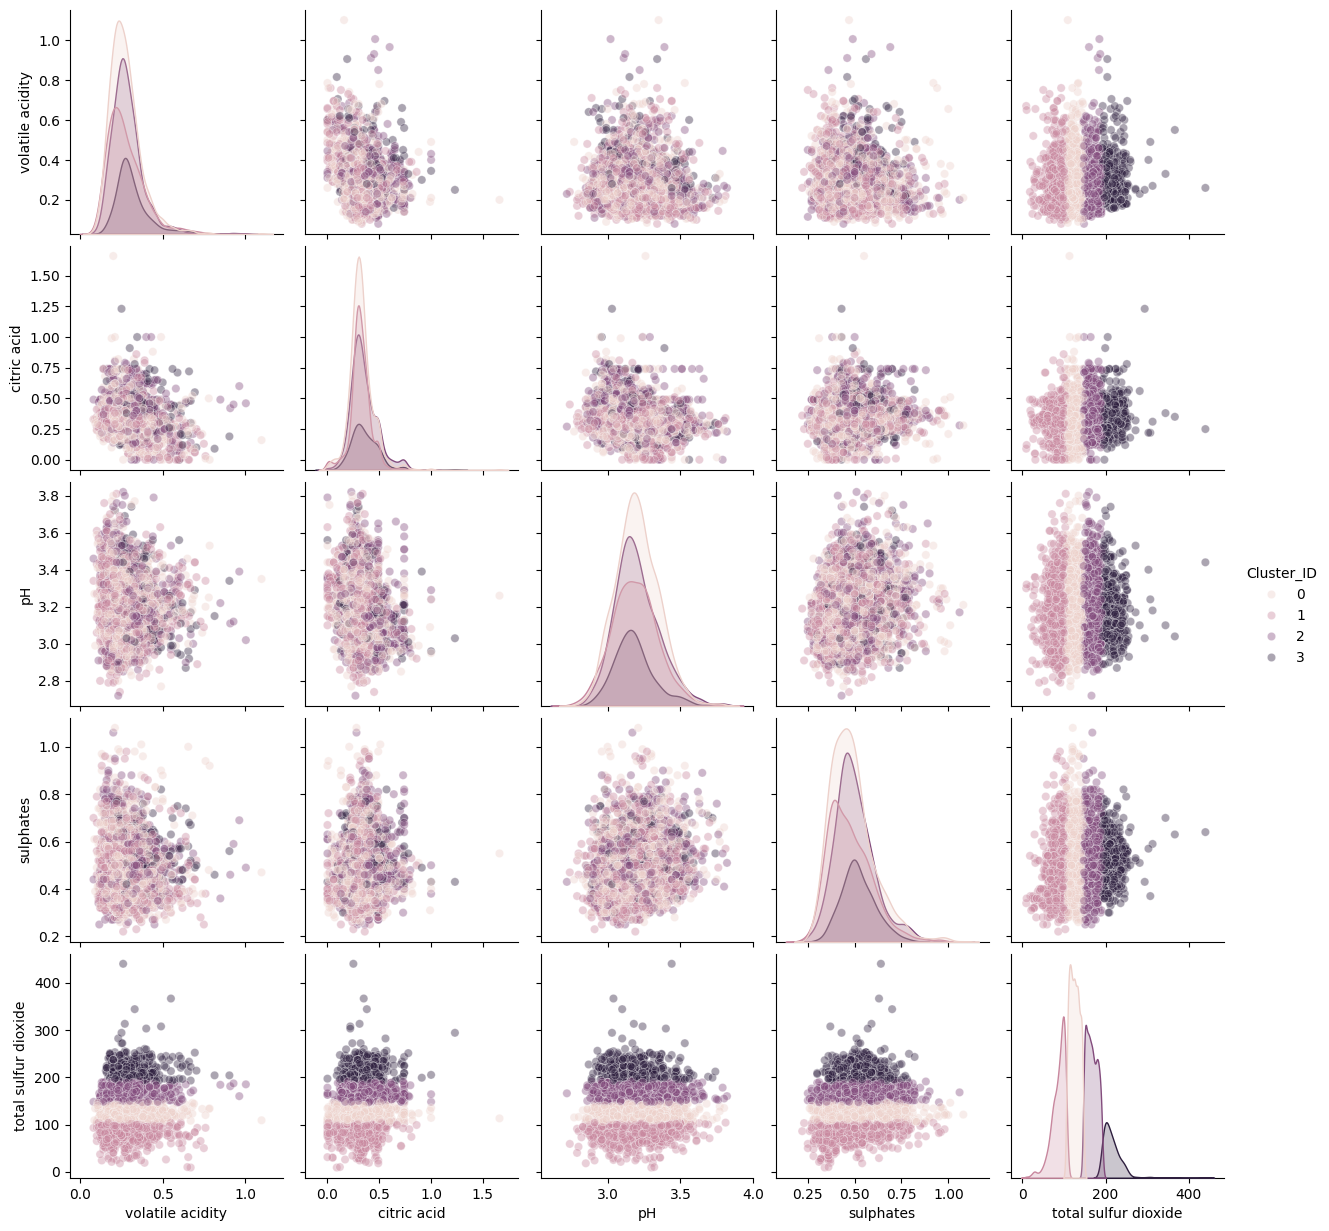

In [108]:
sns.pairplot(
    df_q4,
    hue='Cluster_ID',
    plot_kws={'alpha': 0.4}
)

plt.show()

### Q5

In [109]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# StandardScaler model
standard_scaler = StandardScaler()
X_standard = standard_scaler.fit_transform(df_selected)

model_standard = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

labels_standard = model_standard.fit_predict(X_standard)

sil_standard = silhouette_score(
    X_standard,
    labels_standard
)

print("StandardScaler silhouette:", sil_standard)



# MinMaxScaler model
minmax_scaler = MinMaxScaler()
X_minmax = minmax_scaler.fit_transform(df_selected)

model_minmax = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

labels_minmax = model_minmax.fit_predict(X_minmax)

sil_minmax = silhouette_score(
    X_minmax,
    labels_minmax
)

print("MinMaxScaler silhouette:", sil_minmax)

StandardScaler silhouette: 0.17836234905399023
MinMaxScaler silhouette: 0.19357957233432618


In [110]:
print("Unscaled model:", silhouette_q4)
print("StandardScaler:", sil_standard)
print("MinMaxScaler:", sil_minmax)

Unscaled model: 0.5243291283316336
StandardScaler: 0.17836234905399023
MinMaxScaler: 0.19357957233432618


In [111]:
df_minmax_profile = df_selected.copy()
df_minmax_profile['Cluster_ID'] = labels_minmax

cluster_means = (
    df_minmax_profile
    .groupby('Cluster_ID')[selected_features]
    .mean()
)

print(cluster_means)

            volatile acidity  citric acid        pH  sulphates  \
Cluster_ID                                                       
0                   0.332741     0.357637  3.143347   0.501264   
1                   0.266699     0.293721  3.374385   0.477891   
2                   0.263016     0.342967  3.099608   0.417362   
3                   0.260476     0.346104  3.201849   0.681382   

            total sulfur dioxide  
Cluster_ID                        
0                     185.454404  
1                     129.371582  
2                     114.119314  
3                     127.217235  


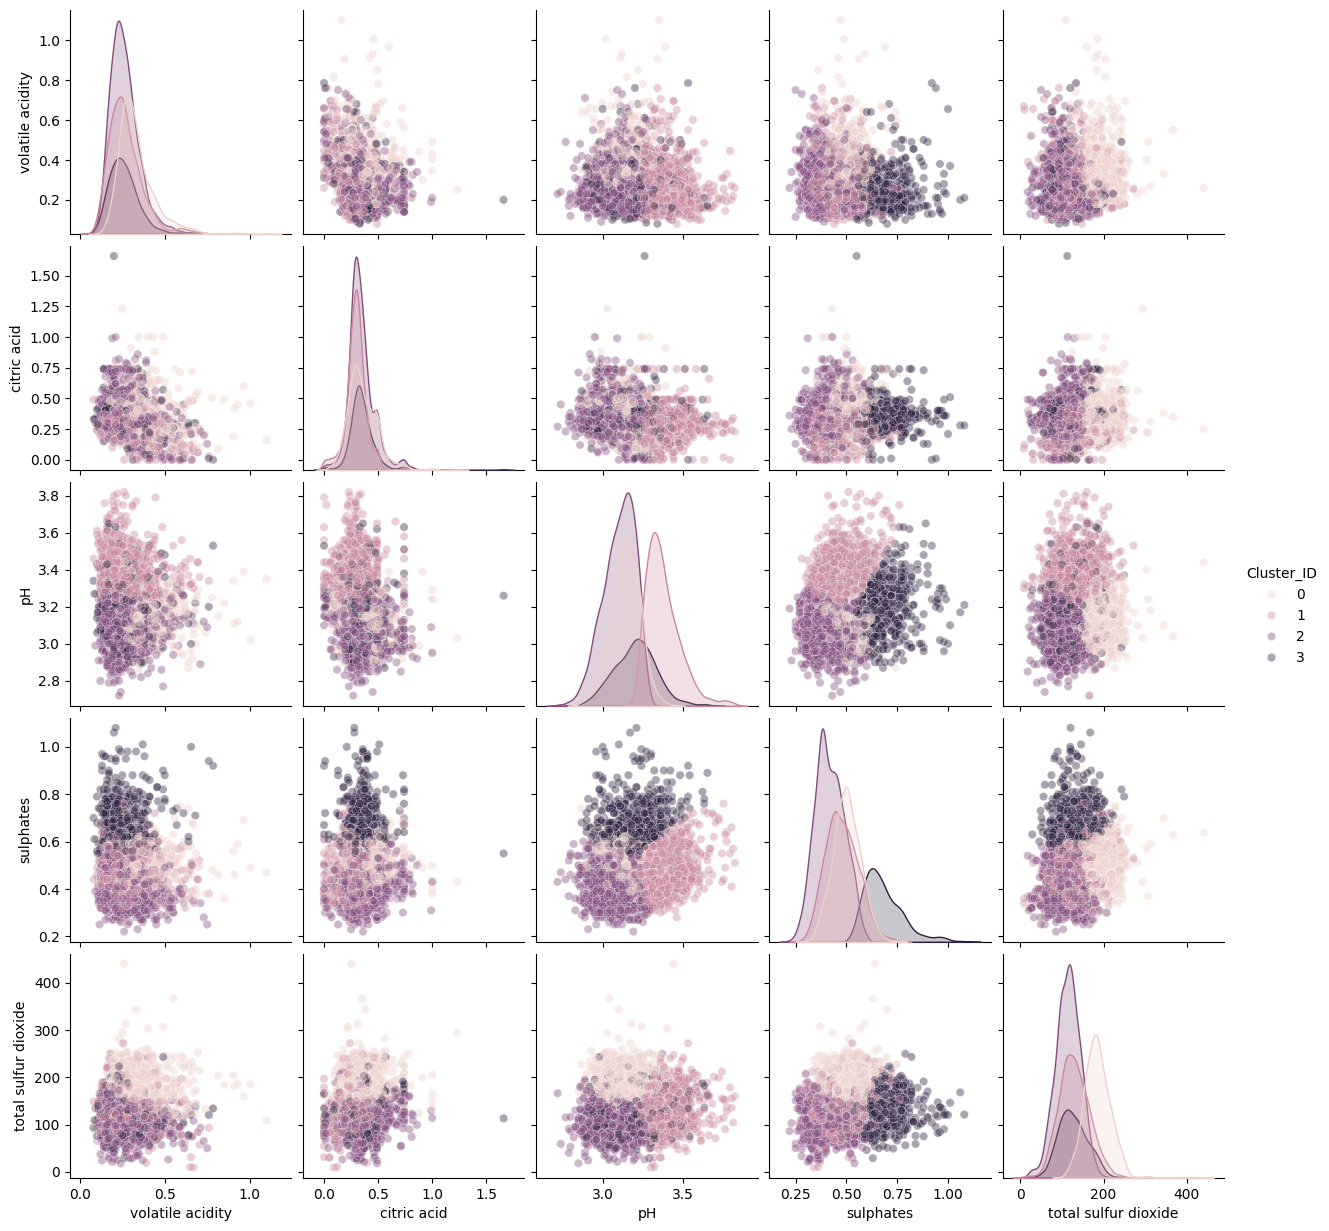

In [112]:
df_minmax = df_selected.copy()
df_minmax['Cluster_ID'] = labels_minmax

sns.pairplot(
    df_minmax,
    hue='Cluster_ID',
    plot_kws={'alpha': 0.4}
)

plt.show()

In [113]:
cluster_profile = (
    df_minmax
    .groupby('Cluster_ID')[selected_features]
    .mean()
)

print(cluster_profile)

            volatile acidity  citric acid        pH  sulphates  \
Cluster_ID                                                       
0                   0.332741     0.357637  3.143347   0.501264   
1                   0.266699     0.293721  3.374385   0.477891   
2                   0.263016     0.342967  3.099608   0.417362   
3                   0.260476     0.346104  3.201849   0.681382   

            total sulfur dioxide  
Cluster_ID                        
0                     185.454404  
1                     129.371582  
2                     114.119314  
3                     127.217235  


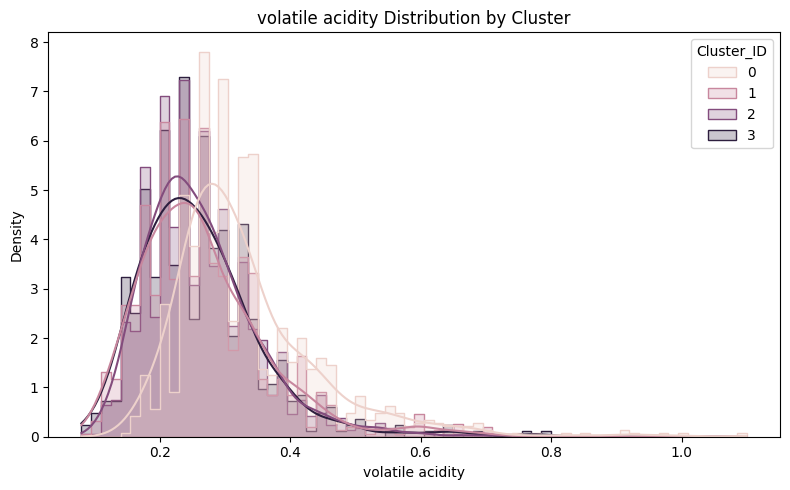

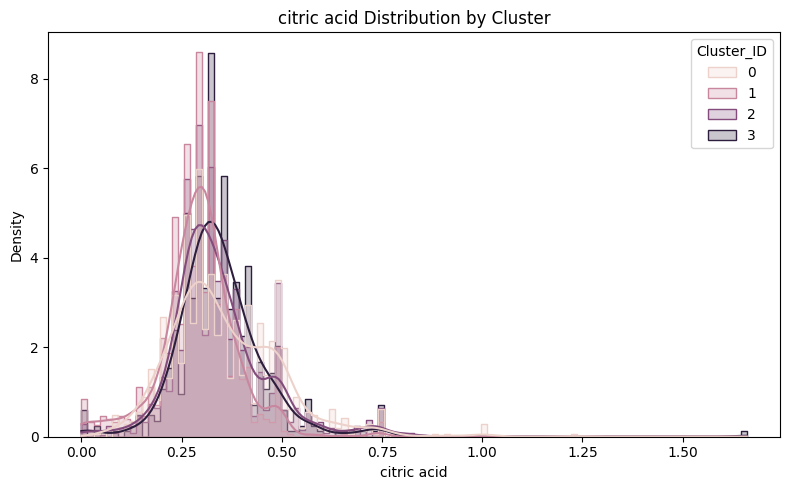

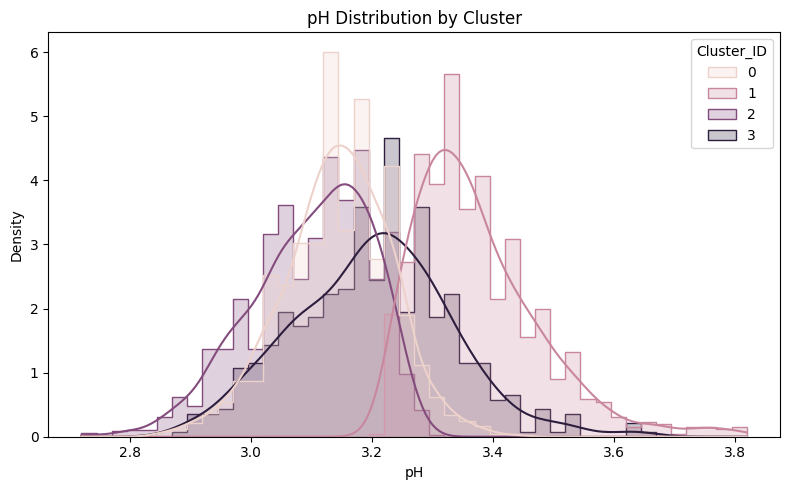

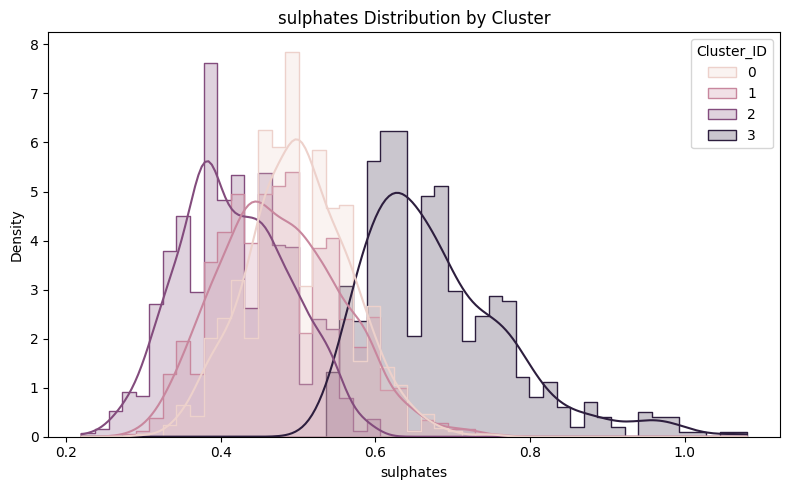

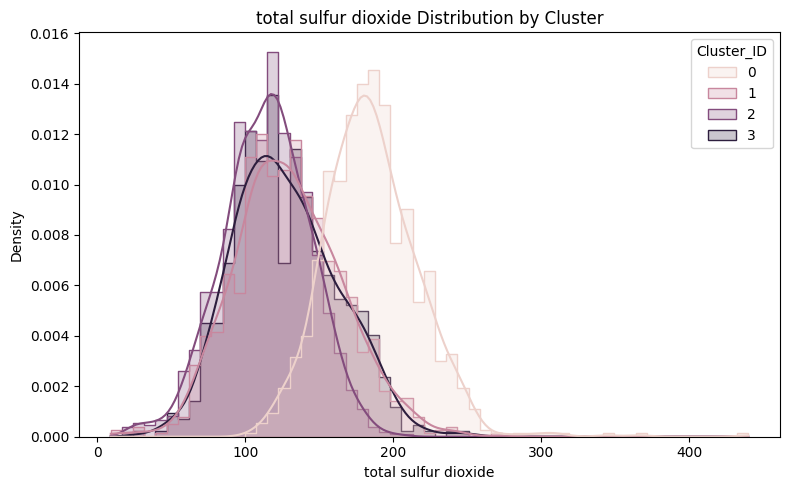

In [114]:
import matplotlib.pyplot as plt
import seaborn as sns

df_minmax_plot = df_selected.copy()
df_minmax_plot['Cluster_ID'] = labels_minmax

for feature in selected_features:
    plt.figure(figsize=(8, 5))

    sns.histplot(
        data=df_minmax_plot,
        x=feature,
        hue='Cluster_ID',
        kde=True,
        element='step',
        stat='density',
        common_norm=False
    )

    plt.title(f'{feature} Distribution by Cluster')
    plt.tight_layout()
    plt.show()